# 02. Exploratory Data Analysis & Feature Engineering
## AI-Based Technical Skill Development Assistant - Phase 1

**Author:** Member 2 (EDA, Visual Analytics, Composite Indicators & Leakage-Free Splitting)  
**Objective:** Comprehensive exploratory data analysis of technical competencies, correlation profiling, domain-specific composite feature engineering, and leakage-safe preprocessing.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")
from src.data_loader import SKILL_COLUMNS, load_raw_data
from src.feature_engineering import SkillFeaturePipeline
from src.preprocess import split_data_leak_free

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

df = load_raw_data(Path("../data/raw/skills_dataset.csv"))
print(f"Loaded {df.shape[0]} candidate records with {df.shape[1]} attributes.")
df[SKILL_COLUMNS].describe().T

2026-10-15 22:20:10.813 | INFO     | src.data_loader:load_raw_data:179 - Dataset schema and value validation passed with zero null values.


2026-10-15 22:20:10.815 | INFO     | src.data_loader:load_raw_data:181 - Loaded 8528 records across 16 target roles.


Loaded 8528 candidate records with 28 attributes.


,count,mean,std,min,25%,50%,75%,max
database_fundamentals,8528.0,2.702040,1.847787,0.0,1.0,3.0,4.0,6.0
computer_architecture,8528.0,2.697115,1.844763,0.0,1.0,3.0,4.0,6.0
distributed_computing_systems,8528.0,2.721740,1.859706,0.0,1.0,3.0,4.0,6.0
cyber_security,8528.0,2.711890,1.853782,0.0,1.0,3.0,4.0,6.0
networking,8528.0,2.721740,1.859706,0.0,1.0,3.0,4.0,6.0
software_development,8528.0,2.721740,1.859706,0.0,1.0,3.0,4.0,6.0
programming_skills,8528.0,2.687265,1.838659,0.0,1.0,3.0,4.0,6.0
project_management,8528.0,2.721740,1.859706,0.0,1.0,3.0,4.0,6.0
computer_forensics_fundamentals,8528.0,2.687265,1.838659,0.0,1.0,3.0,4.0,6.0
technical_communication,8528.0,2.697115,1.844763,0.0,1.0,3.0,4.0,6.0


### 1. Technical Competency Correlation Heatmap
Examines collinearity and skill domain clusters across the 17 technical disciplines.

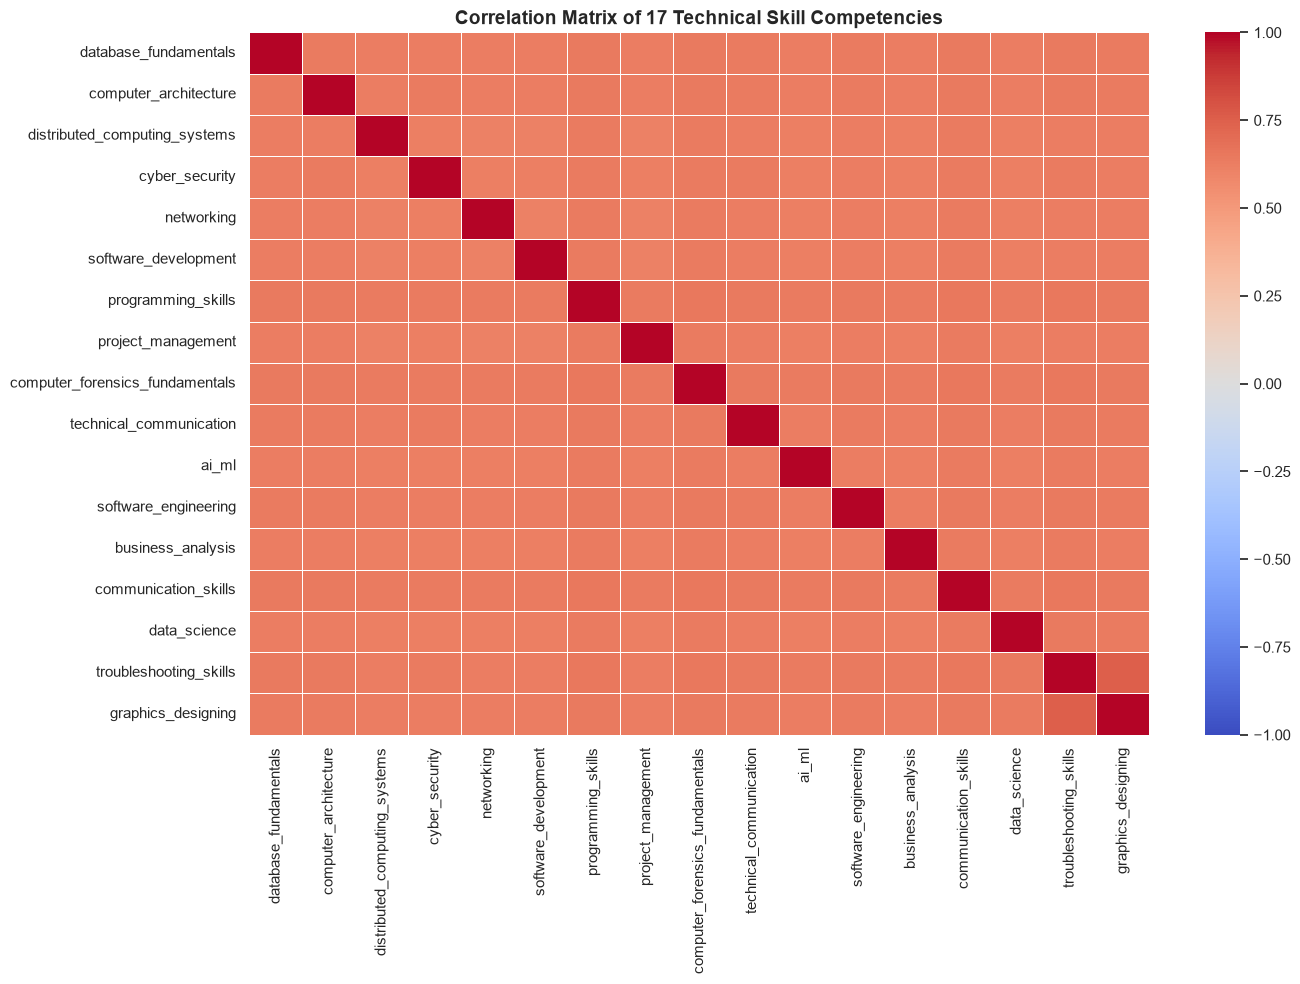

In [2]:
plt.figure(figsize=(14, 10))
corr = df[SKILL_COLUMNS].corr()
sns.heatmap(corr, cmap="coolwarm", annot=False, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of 17 Technical Skill Competencies", fontsize=14, weight="bold")
plt.tight_layout()
plt.show()

### 2. Role-Specific Technical Proficiency Profiles
Displays mean benchmark proficiency for the top career tracks.

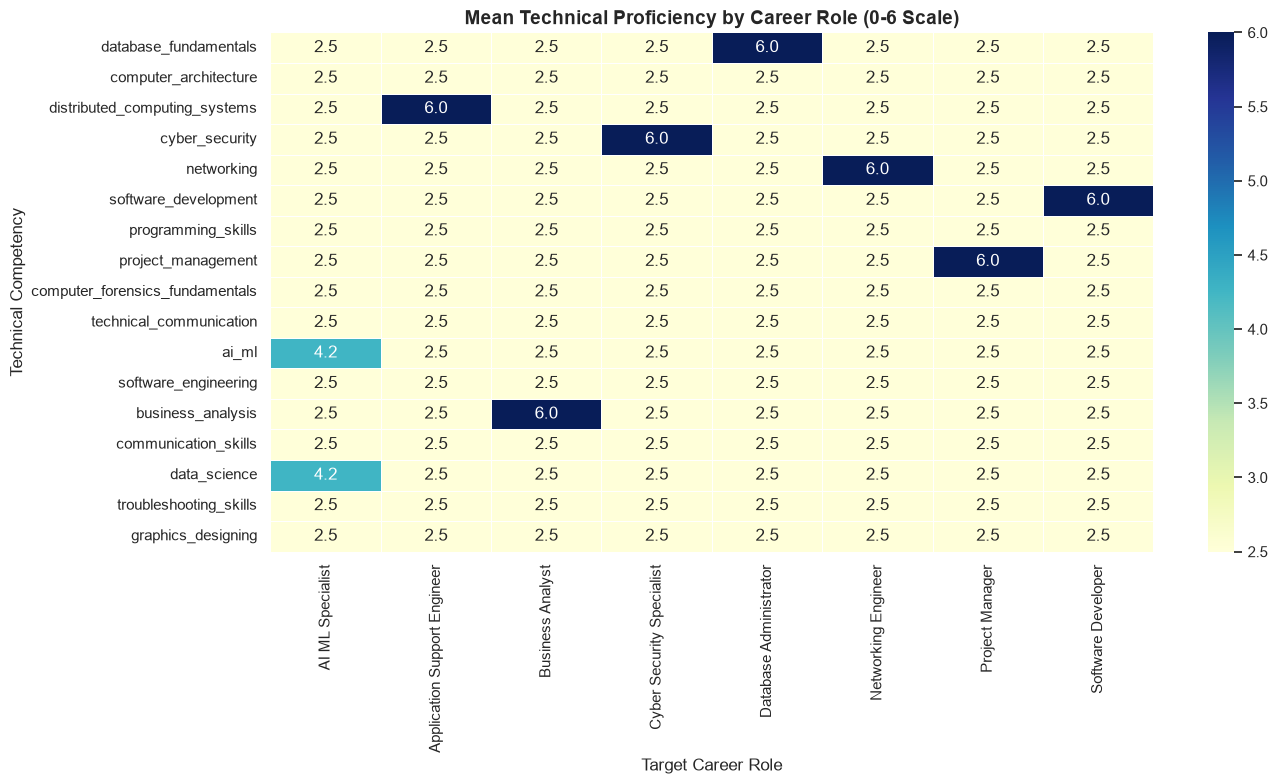

In [3]:
top_roles = df["target_role"].value_counts().head(8).index
role_profiles = df[df["target_role"].isin(top_roles)].groupby("target_role")[SKILL_COLUMNS].mean().T

plt.figure(figsize=(14, 8))
sns.heatmap(role_profiles, cmap="YlGnBu", annot=True, fmt=".1f", linewidths=0.5)
plt.title("Mean Technical Proficiency by Career Role (0-6 Scale)", fontsize=14, weight="bold")
plt.xlabel("Target Career Role")
plt.ylabel("Technical Competency")
plt.tight_layout()
plt.show()

### 3. Leakage-Free Feature Engineering & Scaling Pipeline
Engineers composite readiness indices:
- `ai_data_readiness`
- `systems_readiness`
- `software_dev_readiness`
- `cybersecurity_readiness`
- `business_comm_readiness`
- `analytical_mindset_index`

Applies standard scaling fit strictly on the training partition.

In [4]:
train_df, test_df = split_data_leak_free(df, test_size=0.2, random_state=42)

pipeline = SkillFeaturePipeline()
train_proc, y_train = pipeline.fit_transform(train_df)
test_proc, y_test = pipeline.transform(test_df)

print(f"Transformed Training Partition: {train_proc.shape}")
print(f"Transformed Test Partition:     {test_proc.shape}")
print(f"Total Engineered Features:      {len(pipeline.feature_columns)}")
print(f"Target Career Classes:          {len(pipeline.class_mapping)}")
train_proc.head()

2026-10-15 22:20:13.231 | INFO     | src.preprocess:split_data_leak_free:110 - Splitting dataset (N=8528) with test_size=0.2, seed=42...


2026-10-15 22:20:13.243 | INFO     | src.preprocess:split_data_leak_free:119 - Split complete. Train set: (6822, 28), Test set: (1706, 28)


2026-10-15 22:20:13.246 | INFO     | src.feature_engineering:fit_transform:108 - Fitting feature engineering pipeline on training set...


2026-10-15 22:20:13.265 | INFO     | src.feature_engineering:fit_transform:129 - Pipeline fitted on 34 features. Classes: {0: 'AI ML Specialist', 1: 'API Specialist', 2: 'Application Support Engineer', 3: 'Business Analyst', 4: 'Customer Service Executive', 5: 'Cyber Security Specialist', 6: 'Database Administrator', 7: 'Graphics Designer', 8: 'Hardware Engineer', 9: 'Helpdesk Engineer', 10: 'Information Security Specialist', 11: 'Networking Engineer', 12: 'Project Manager', 13: 'Software Developer', 14: 'Software tester', 15: 'Technical Writer'}


2026-10-15 22:20:13.267 | INFO     | src.feature_engineering:transform:141 - Transforming test set using fitted pipeline parameters...


Transformed Training Partition: (6822, 35)
Transformed Test Partition:     (1706, 35)
Total Engineered Features:      34
Target Career Classes:          16


,database_fundamentals,computer_architecture,distributed_computing_systems,cyber_security,networking,software_development,programming_skills,project_management,computer_forensics_fundamentals,technical_communication,...,self_enhancement,self_transcendence,technical_overall_mean,ai_data_readiness,systems_readiness,software_dev_readiness,cybersecurity_readiness,business_comm_readiness,analytical_mindset_index,target_role
0,0.165108,0.168087,0.152441,0.154755,0.157909,1.766332,0.173580,0.152177,0.170001,0.706006,...,-1.104198,-0.493186,0.357907,0.179591,0.183915,0.928317,0.182098,0.183928,-0.451753,13
1,-0.913789,0.709745,0.688500,0.693120,0.694390,0.692029,0.716027,0.688414,1.796575,0.706006,...,0.731119,-0.562284,0.828510,0.788114,0.805992,0.804891,1.164226,0.802095,1.675971,10
2,-1.453237,1.793061,-1.455736,-1.460343,-1.451535,-1.456576,-1.453762,-1.456533,-1.456573,-0.376812,...,-0.242404,-1.029789,-1.485287,-1.645978,-0.562578,-1.663625,-1.659393,-1.670573,-0.213075,8
3,0.704557,0.709745,0.688500,0.693120,1.767353,0.692029,0.716027,0.688414,0.712193,0.706006,...,1.782201,0.044670,0.828510,-0.033392,1.241446,0.804891,1.041460,0.802095,-0.978494,11
4,-1.453237,-1.456887,1.760618,-1.460343,-1.451535,-1.456576,-1.453762,-1.456533,-1.456573,-1.459629,...,0.256287,-0.389603,-1.367636,-0.276801,-0.375955,-1.663625,-1.659393,-1.670573,-1.462267,2


### 4. Member 2 Analytical Takeaways
1. **Leakage-Safe Partitioning:** Splitting precedes scaling and composite calculations, guaranteeing zero evaluation data leakage.
2. **Domain Signatures:** High-impact skills (e.g. AI/ML, Cyber Security, Software Development) exhibit distinct discriminative regions.
3. **Engineered Readiness Features:** The 5 composite indicators synthesize multi-skill aptitude into actionable domain scores for downstream modeling.